# 🛒 E-Commerce Product Clustering (Unsupervised ML)

**Goal:** group 6,000 real Amazon products into meaningful clusters **without using any labels**,
based on their title, description, price, rating and number of reviews.

**Why it matters:** catalogue cleanup, "customers also viewed" recommendations, discovering hidden product segments.

**Dataset:** Amazon Reviews 2023 product metadata (McAuley Lab, UC San Diego), via Hugging Face
`milistu/AMAZON-Products-2023`. Created with `python download_data.py` → `products.csv`.

### Steps
1. Load & explore the data
2. Feature engineering (text → numbers, scale numbers)
3. Choose the number of clusters K (Elbow + Silhouette)
4. Train K-Means
5. Understand the clusters (keywords, profiles)
6. Visualise (PCA 2-D)
7. Check against Amazon's real categories
8. Compare K-Means vs Agglomerative vs DBSCAN
9. Predict the cluster of a new product + find similar products

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler, Normalizer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load & explore the data
`true_category` is Amazon's own category. **The model never sees it.** We keep it only to check our clusters at the end (like an answer key).

In [2]:
df = pd.read_csv("products.csv")
df["text"] = df["title"].fillna("") + " " + df["description"].fillna("")   # one text column for the model
print(df.shape)
df.head()

(6000, 8)


,product_id,title,description,price,rating,num_reviews,true_category,text
0,1,"BigNoseDeer Ceramic flower Coffee Mug, Creative Cute Cup with cloud Sunflowe...","Cute mugs, add a decorative touch to your décor Easy to clean, healthy and s...",24.49,4.4,40,Amazon Home,"BigNoseDeer Ceramic flower Coffee Mug, Creative Cute Cup with cloud Sunflowe..."
1,2,MEGIR Men's Analogue Sport Chronograph Luminous Quartz Watch with Fashion Si...,MEGIR 时尚休闲奢华经典男士模拟运动商务工作石英腕表硅胶表带计时日历夜光防水,36.99,4.5,831,AMAZON FASHION,MEGIR Men's Analogue Sport Chronograph Luminous Quartz Watch with Fashion Si...
2,3,HQRP 110V LED Light Bulb Cool White Compatible with Bernina 700/710 / 802 / ...,HQRP BA15d Base 64 LEDs SMD 3014 LED Sewing Machine Light Bulb Cool White 60...,5.91,1.7,2,Tools & Home Improvement,HQRP 110V LED Light Bulb Cool White Compatible with Bernina 700/710 / 802 / ...
3,4,MY KILOMETRE Womens Cycling Bike Bib Shorts Women Bicycle Riding Pants Padde...,The Women's Training Bib Shorts feature a host of MK's fabric technologies a...,56.99,4.5,37,AMAZON FASHION,MY KILOMETRE Womens Cycling Bike Bib Shorts Women Bicycle Riding Pants Padde...
4,5,Zuoyouzi Women's Notch V Neck Ruffle Short Sleeve Casual Shirts Pleated Pepl...,Zuoyouzi Women's Notch V Neck Ruffle Short Sleeve Casual Shirts Pleated Pepl...,23.99,3.7,7,AMAZON FASHION,Zuoyouzi Women's Notch V Neck Ruffle Short Sleeve Casual Shirts Pleated Pepl...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     6000 non-null   int64  
 1   title          6000 non-null   object 
 2   description    6000 non-null   object 
 3   price          6000 non-null   float64
 4   rating         6000 non-null   float64
 5   num_reviews    6000 non-null   int64  
 6   true_category  6000 non-null   object 
 7   text           6000 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 375.1+ KB


In [4]:
df[['price', 'rating', 'num_reviews']].describe().round(2)

,price,rating,num_reviews
count,6000.00,6000.00,6000.00
mean,43.57,4.14,144.54
std,90.14,0.88,1169.56
min,0.29,1.00,1.00
25%,11.99,3.90,4.00
50%,19.88,4.40,14.00
75%,36.01,4.70,38.00
max,1699.99,5.00,43896.00


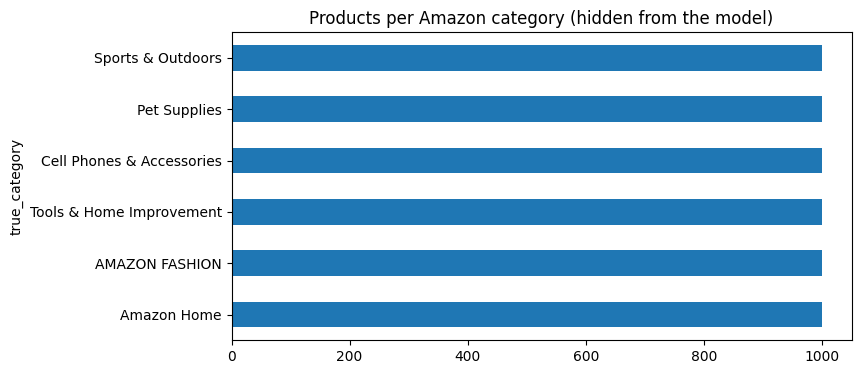

In [5]:
df["true_category"].value_counts().plot.barh(title="Products per Amazon category (hidden from the model)")
plt.show()

**Price and review counts are skewed**: many cheap products, a few very expensive ones.
Taking `log` makes the distribution much more even, so a few expensive items don't dominate the distances.

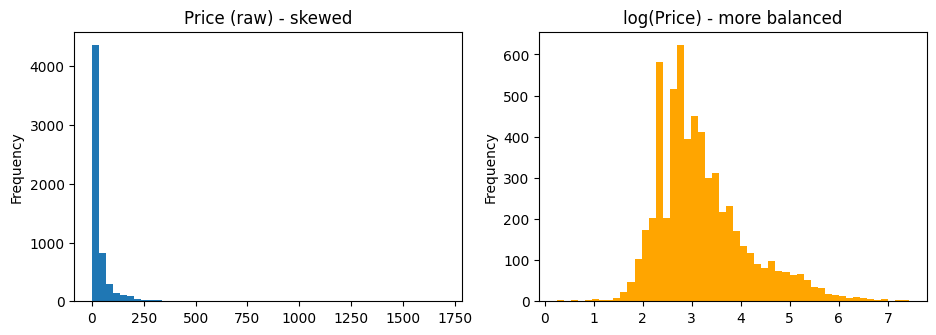

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["price"].plot.hist(bins=50, ax=ax[0], title="Price (raw) - skewed")
np.log1p(df["price"]).plot.hist(bins=50, ax=ax[1], title="log(Price) - more balanced", color="orange")
plt.show()

## 2. Feature engineering
K-Means only understands numbers, so every product becomes a vector of numbers.

**Text (title + description):**
- **TF-IDF**: score each word: high if frequent in *this* product but rare overall ("dog" is informative, "the" is not)
  - `sublinear_tf=True` repeated words count less; `max_df=0.5` drop words found in more than half the products
- **Truncated SVD**: compress thousands of word columns into **50 "topics"** (also called LSA)
- **Normalizer**: make every text vector length 1

**Numbers:** `log` on price & reviews, then **StandardScaler** (mean 0, std 1) so all are on the same scale.

**Weights:** text = 1.0, numbers = 0.1 → text decides *what* a product is; numbers only nudge.

### What does TF-IDF see? (one example product)

In [7]:
tfidf_demo = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_df=0.5)
M = tfidf_demo.fit_transform(df["text"])
print("Vocabulary size:", M.shape[1], "words/phrases\n")

i = 0
print("Product:", df.loc[i, "title"], "\n")
row = pd.Series(M[i].toarray().ravel(), index=tfidf_demo.get_feature_names_out())
row.sort_values(ascending=False).head(8).round(3)

Vocabulary size: 45899 words/phrases

Product: BigNoseDeer Ceramic flower Coffee Mug, Creative Cute Cup with cloud Sunflower Coaster for Office and Home, 6.5 oz/200 ml for Tea Latte Milk 



mug            0.231
mug perfect    0.199
coaster        0.189
tea            0.178
coffee mug     0.171
cloud          0.170
mugs           0.164
milk           0.160
dtype: float64

### Build the full feature pipeline

In [8]:
text_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_df=0.5)),
    ("svd", TruncatedSVD(n_components=50, random_state=42)),
    ("norm", Normalizer()),
])

features = ColumnTransformer(
    [("text", text_pipe, "text"),
     ("skewed", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["price", "num_reviews"]),
     ("normal", StandardScaler(), ["rating"])],
    transformer_weights={"text": 1.0, "skewed": 0.1, "normal": 0.1},
)

X = features.fit_transform(df)
print("Feature matrix:", X.shape, f"-> {len(df)} products x (50 text topics + 3 numbers)")

Feature matrix: (6000, 53) -> 6000 products x (50 text topics + 3 numbers)


## 3. Choose K (how many clusters?)
- **Elbow method:** inertia = total squared distance of products to their cluster centre. Always falls as K grows → look for the *bend*.
- **Silhouette score:** −1 to 1. How much closer a product is to its own cluster than to the next one. Higher = better.

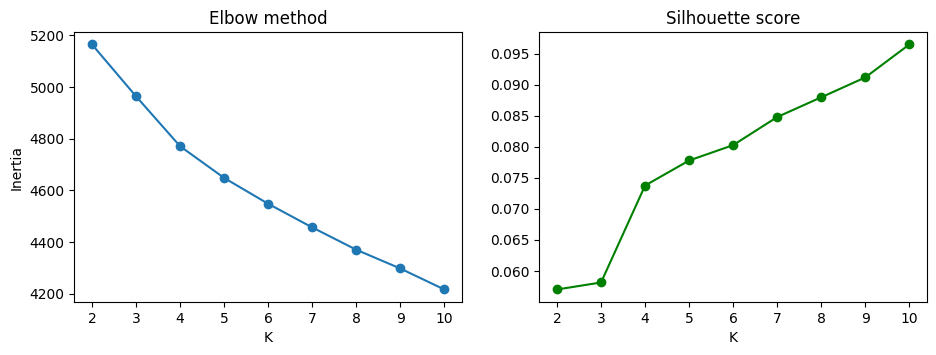

,k,inertia,silhouette
0,2,5164.559,0.057
1,3,4963.692,0.058
2,4,4770.529,0.074
3,5,4647.853,0.078
4,6,4547.688,0.080
5,7,4456.239,0.085
6,8,4369.799,0.088
7,9,4297.114,0.091
8,10,4215.852,0.097


In [9]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
scores = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(scores.k, scores.inertia, "o-");  ax[0].set(title="Elbow method", xlabel="K", ylabel="Inertia")
ax[1].plot(scores.k, scores.silhouette, "o-", color="green"); ax[1].set(title="Silhouette score", xlabel="K")
plt.show()
scores.round(3)

**Reading the charts:** silhouette grows slowly with no sharp peak, normal for text data (many dimensions, products overlap).
We pick **K = 6**: the elbow flattens around there and 6 groups are easy for a business to understand and use.

## 4. Train K-Means (K = 6)
How K-Means works:
1. Pick K random centres
2. Assign every product to its nearest centre
3. Move each centre to the average of its products
4. Repeat until nothing changes

`n_init=10` → run 10 times from different starts, keep the best.

In [10]:
K = 6
model = Pipeline([("features", features), ("kmeans", KMeans(n_clusters=K, n_init=10, random_state=42))])
model.fit(df)
df["cluster"] = model.named_steps["kmeans"].labels_
df["cluster"].value_counts().sort_index()

cluster
0     832
1     932
2     257
3    1898
4     876
5    1205
Name: count, dtype: int64

## 5. Understand the clusters
For each cluster: size, average price/rating, and the **top keywords** (words with the highest average TF-IDF in that cluster).

In [11]:
tfidf = model.named_steps["features"].named_transformers_["text"].named_steps["tfidf"]
M, terms = tfidf.transform(df["text"]), tfidf.get_feature_names_out()

def top_words(c, n=6):
    mean_scores = np.asarray(M[(df.cluster == c).values].mean(axis=0)).ravel()
    return ", ".join(terms[mean_scores.argsort()[::-1][:n]])

profile = df.groupby("cluster").agg(products=("title", "count"), avg_price=("price", "mean"),
                                    avg_rating=("rating", "mean"), median_reviews=("num_reviews", "median")).round(1)
profile["top_keywords"] = [top_words(c) for c in profile.index]
profile

,products,avg_price,avg_rating,median_reviews,top_keywords
cluster,,,,,
0,832,27.2,4.1,16.0,"dog, dogs, cat, pet, cats, toy"
1,932,43.9,4.1,18.0,"women, men, sleeve, shirt, casual, comfort"
2,257,40.1,4.1,15.0,"light, led, lights, lamp, solar, lighting"
3,1898,59.9,4.2,15.0,"steel, water, bag, stainless, size, easy"
4,876,27.1,4.1,12.0,"case, phone, galaxy, samsung, compatible, cover"
5,1205,41.7,4.2,9.0,"storage, home, set, room, gift, size"


### A few example products from each cluster

In [12]:
for c in range(K):
    print(f"--- Cluster {c}: {top_words(c, 4)}")
    for t in df[df.cluster == c]["title"].head(3):
        print("   •", t[:90])

--- Cluster 0: dog, dogs, cat, pet
   • voloki 10pcs Bird Cuttlebone Easy to Absorb Natural Cuddle Bone Safety Chewing Cuttlefish 
   • Licputalch 2Pcs Flying Bird Cat Toy, Bird Interactive Cat Toy, Automatic Hanging Eagle Fly
   • Susenc Automatic Cat Toys Interactive Cat Feather Toy for Indoor Cats, 360 Degree Irregula
--- Cluster 1: women, men, sleeve, shirt
   • MEGIR Men's Analogue Sport Chronograph Luminous Quartz Watch with Fashion Silicone Strap
   • MY KILOMETRE Womens Cycling Bike Bib Shorts Women Bicycle Riding Pants Padded Cycle Bib Sh
   • Zuoyouzi Women's Notch V Neck Ruffle Short Sleeve Casual Shirts Pleated Peplum Tunic Tops 
--- Cluster 2: light, led, lights, lamp
   • HQRP 110V LED Light Bulb Cool White Compatible with Bernina 700/710 / 802 / 802S / 831/832
   • EverGrow 7 Watts G23 Base UV-C Ultraviolet Light Bulb Qty 2
   • KEYGMA 6 Pairs Male/Female Solar Panel Cable Connectors, 2 Pieces Spanners for PV Solar Co
--- Cluster 3: steel, water, bag, stainless
   • Litt

## 6. Visualise with PCA
We have 53 features, and humans can only see 2. **PCA** squeezes them into the 2 directions with the most variation.
Some overlap in 2-D is expected; clusters are better separated in the full 53-D space.

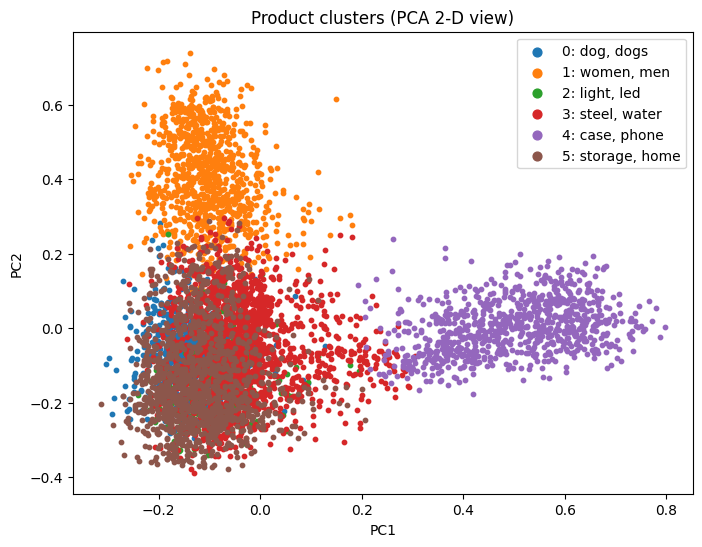

In [13]:
xy = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(8, 6))
for c in range(K):
    m = (df.cluster == c).values
    plt.scatter(xy[m, 0], xy[m, 1], s=10, label=f"{c}: {top_words(c, 2)}")
plt.legend(markerscale=2); plt.title("Product clusters (PCA 2-D view)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

## 7. Check against Amazon's real categories
Now (and only now) we use the hidden `true_category` to evaluate.

**ARI (Adjusted Rand Index):** 0 = random grouping, 1 = perfect match.

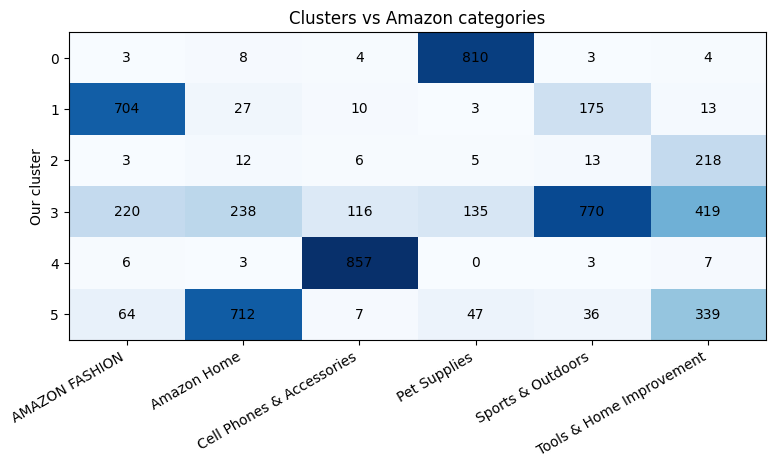

ARI: 0.412


In [14]:
table = pd.crosstab(df["cluster"], df["true_category"])
plt.figure(figsize=(9, 4))
plt.imshow(table, cmap="Blues", aspect="auto")
plt.xticks(range(table.shape[1]), table.columns, rotation=30, ha="right"); plt.yticks(range(K))
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        plt.text(j, i, table.iloc[i, j], ha="center", va="center")
plt.ylabel("Our cluster"); plt.title("Clusters vs Amazon categories"); plt.show()

print("ARI:", round(adjusted_rand_score(df["true_category"], df["cluster"]), 3))

**Interpretation:** pets and phone-accessories clusters match Amazon's categories almost one-to-one, without ever seeing labels.
The rest overlap because Amazon's own categories overlap (a water bottle can be *Sports*, *Home* or *Tools*),
and clustering found new groups such as **lighting**.

## 8. Compare algorithms
| Algorithm | Idea |
|---|---|
| **K-Means** | nearest centre |
| **Agglomerative (Ward)** | start with every product alone, keep merging the two closest groups |
| **DBSCAN** | clusters = dense regions; points in sparse areas = noise (label −1) |

Metrics: **Silhouette** ↑ better · **Davies-Bouldin** ↓ better · **ARI** ↑ better

In [15]:
algos = {
    "K-Means": KMeans(n_clusters=K, n_init=10, random_state=42),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=K),
    "DBSCAN": DBSCAN(eps=0.6, min_samples=10),
}
results = []
for name, algo in algos.items():
    labels = algo.fit_predict(X)
    keep = labels != -1                      # ignore DBSCAN noise for the scores
    results.append({
        "Algorithm": name,
        "Clusters": len(set(labels[keep])),
        "Noise points": int((~keep).sum()),
        "Silhouette ↑": round(silhouette_score(X[keep], labels[keep]), 3),
        "Davies-Bouldin ↓": round(davies_bouldin_score(X[keep], labels[keep]), 3),
        "ARI ↑": round(adjusted_rand_score(df["true_category"], labels), 3),
    })
pd.DataFrame(results)

,Algorithm,Clusters,Noise points,Silhouette ↑,Davies-Bouldin ↓,ARI ↑
0,K-Means,6,0,0.080,3.508,0.412
1,Agglomerative (Ward),6,0,0.067,3.559,0.331
2,DBSCAN,35,2464,0.114,1.562,0.186


**Conclusion:** DBSCAN's silhouette *looks* best, but it threw ~40% of products away as noise, scored only the leftovers, and split them into dozens of tiny clusters.
Text data has no clear dense regions. **K-Means gives the best balance** (best silhouette among methods that keep every product, and best ARI).

## 9. Predict a new product's cluster + recommend similar products
The model is one pipeline, so new products go through the exact same steps automatically.

In [16]:
new = pd.DataFrame([{
    "title": "Stainless steel dog food bowl, non-slip",
    "description": "Durable bowl for small and medium dogs and cats",
    "price": 14.99, "rating": 4.5, "num_reviews": 120,
}])
new["text"] = new["title"] + " " + new["description"]

c = model.predict(new)[0]
print(f"Predicted cluster: {c}  ({top_words(c)})\n")

sims = cosine_similarity(model.named_steps["features"].transform(new), X)[0]
print("Most similar products ('customers also viewed'):")
df.assign(similarity=sims.round(3)).nlargest(5, "similarity")[["title", "price", "similarity"]]

Predicted cluster: 0  (dog, dogs, cat, pet, cats, toy)

Most similar products ('customers also viewed'):


,title,price,similarity
5885,"Niubya Elevated Dog Bowls with 2 Stainless Steel Dog Food Bowls, Raised Dog ...",25.99,0.933
5758,"Dog Bowls 2 Pack, Stainless Steel Dog Food Bowl and Water Bowl, Hanging Dog ...",18.99,0.931
4539,"Slow Feeder Insert,Oimaigroo Silicon Rubber Pet Slow Feeder Slow Down Eating...",11.99,0.856
5567,Sazeepetz Stainless Steel Slow Feed Premium Dog or Cat Bowl Set of 2 (Slow F...,22.97,0.848
1742,"VavoPaw Pet Slow Feeder Dog Bowl, Slow Feeding Ceramic Dog Bowl, Pet Anxiety...",25.99,0.797


## 10. Summary
- Grouped **6,000 real Amazon products** into **6 clusters** with **no labels**
- Pipeline: **TF-IDF → SVD → scaling → K-Means**, with K chosen by **Elbow + Silhouette**
- Clusters are meaningful (pets, phone accessories, clothing, lighting, …) and match Amazon's categories far better than random (ARI ≈ 0.41)
- **K-Means** beat Agglomerative and DBSCAN on this data
- Works for **new products** and gives **similar-product recommendations**

**Limitations / future work:** TF-IDF only matches exact words ("sofa" ≠ "couch") → use sentence embeddings (BERT);
add product images; Gaussian Mixture Models for soft clusters; re-cluster the broad "home/general" group.